# Is this annotation any good? A Xenium breast section, end to end

This tutorial scores a cell-type annotation of one public **10x Xenium** section without any ground truth:

1. **Signal QC** - is there real signal in the data before any label is put on it?
2. **An annotation** - Leiden clusters on PCA, named with a curated breast marker dictionary.
3. **The reference-free battery** - are the labels coherent in expression space, do they track their marker
   programs, how clean are the markers, how decisive is each cell?
4. **Spatial label quality** - do the labels make spatial sense, and how much signal spills in from
   neighbouring cells?

Every number is followed by what it means in plain words. The last section records the wall time and peak
memory of each step on the full section (167,780 cells).

**Data.** *Xenium FFPE Human Breast Cancer, Rep1* (10x Genomics; Janesick et al., *Nat Commun* 2023,
[10.1038/s41467-023-43458-x](https://doi.org/10.1038/s41467-023-43458-x)), licensed
[CC BY 4.0](https://creativecommons.org/licenses/by/4.0/); 313-gene panel plus 228 negative-control probes and
codewords. The data cell below downloads what it needs from 10x:

| File | Size | Needed for |
|---|---|---|
| `..._cell_feature_matrix.h5` | 12.1 MB | everything |
| `..._cells.csv.gz` | 7.9 MB | coordinates, cell areas |
| `..._transcripts.parquet` | 670 MB | transcript QC only (skip with `SAM_FETCH_TRANSCRIPTS=0`) |

**Run it.** `pip install "spatial-anno-metrics[spatial] @ git+https://github.com/p-gueguen/spatial-anno-metrics" scanpy igraph leidenalg pyarrow`,
then run all cells. On our server the computation took under 2 minutes with a 4 GB memory peak, plus the
download (section 6 has the per-step numbers).
Environment variables: `SAM_XENIUM_DIR` (download folder, default `./xenium_breast_rep1`), `SAM_SECTION_H5AD`
(read an AnnData already built by the data cell and skip the matrix download), `SAM_FETCH_TRANSCRIPTS=0`.

In [1]:
import contextlib
import hashlib
import logging
import os
import shutil
import time
import urllib.request
import warnings
from importlib.metadata import version
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp

import spatial_anno_metrics as sam

warnings.simplefilter("ignore", FutureWarning)   # squidpy/scanpy deprecation notices, not results
warnings.filterwarnings("ignore", message="IProgress not found")
import squidpy  # noqa: E402, F401  (after the filters; imported only to quiet its graph-building log)

logging.getLogger("spatialdata._logging").setLevel(logging.WARNING)
plt.rcParams.update({"figure.dpi": 72, "savefig.dpi": 72})   # small PNGs keep the notebook light
pd.set_option("display.width", 140)
pd.set_option("display.precision", 3)
print(" | ".join(f"{p} {version(p)}" for p in ("scanpy", "anndata", "squidpy")),
      "| spatial-anno-metrics", sam.__version__)

PERF = []   # one row per timed step: wall time and peak resident memory of this process


def _proc_gb(field):
    with open("/proc/self/status") as f:
        return next(int(line.split()[1]) for line in f if line.startswith(field)) / 2**20


@contextlib.contextmanager
def timed(step, n_cells):
    """Record wall time and peak RSS of the enclosed code.

    Linux only (NaN elsewhere): writing 5 to /proc/self/clear_refs resets the process's peak-RSS counter
    (VmHWM), so each step gets its own peak.
    """
    try:
        with open("/proc/self/clear_refs", "w") as f:
            f.write("5")
        start = _proc_gb("VmRSS:")
    except OSError:
        start = float("nan")
    t = time.perf_counter()
    yield
    try:
        peak = _proc_gb("VmHWM:")
    except OSError:
        peak = float("nan")
    PERF.append({"step": step, "n_cells": n_cells, "wall_s": round(time.perf_counter() - t, 1),
                 "rss_at_start_gb": round(start, 2), "peak_rss_gb": round(peak, 2)})

scanpy 1.12.5 | anndata 0.13.4 | squidpy 1.8.4 | spatial-anno-metrics unknown


## 1. Data

The data cell downloads the cell-feature matrix and the cell table, checks their md5, and builds an AnnData:
raw counts in `X` and `layers["counts"]`, centroids in `obsm["spatial"]`, and `var["control"]` flagging the
228 negative-control probes and codewords (the package finds controls through this column).

In [2]:
BASE = "https://cf.10xgenomics.com/samples/xenium/1.0.1/Xenium_FFPE_Human_Breast_Cancer_Rep1/"
PREFIX = "Xenium_FFPE_Human_Breast_Cancer_Rep1_"
MD5 = {"cell_feature_matrix.h5": "3bfd29015fa8bacb821d9c9ee86bedaa",   # 12.1 MB
       "cells.csv.gz": "5bbac58bb5edd91bc577603587b6d04e",             # 7.9 MB
       "transcripts.parquet": "54fe44356d0284a39cffd6658a167f06"}      # 670 MB, transcript QC only
DATA = Path(os.environ.get("SAM_XENIUM_DIR", "xenium_breast_rep1"))
SECTION = os.environ.get("SAM_SECTION_H5AD")
FETCH_TRANSCRIPTS = os.environ.get("SAM_FETCH_TRANSCRIPTS", "1") == "1"


def fetch(name):
    """Download BASE + PREFIX + name into DATA (unless already there) and check its md5."""
    path = DATA / (PREFIX + name)
    if not path.exists():
        DATA.mkdir(parents=True, exist_ok=True)
        req = urllib.request.Request(BASE + PREFIX + name, headers={"User-Agent": "curl/8"})  # 403 without one
        with urllib.request.urlopen(req) as r, open(path, "wb") as f:
            shutil.copyfileobj(r, f)
    md5 = hashlib.md5()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1 << 24), b""):
            md5.update(block)
    if md5.hexdigest() != MD5[name]:
        raise ValueError(f"md5 mismatch for {path}: delete it and run the cell again")
    return path


def build_section():
    """Build the AnnData from the 10x cell-feature matrix and cell table."""
    import h5py

    with h5py.File(fetch("cell_feature_matrix.h5"), "r") as f:
        m = f["matrix"]
        n_feat, n_cells = (int(v) for v in m["shape"][:])
        # 10x stores features x cells as CSC: the same arrays read as cells x features CSR
        X = sp.csr_matrix((m["data"][:], m["indices"][:], m["indptr"][:]), shape=(n_cells, n_feat))
        var = pd.DataFrame({k: m["features"][k][:].astype(str) for k in ("id", "name", "feature_type")})
        barcodes = m["barcodes"][:].astype(str)
    cells = pd.read_csv(fetch("cells.csv.gz"))
    assert (cells["cell_id"].astype(str).to_numpy() == barcodes).all(), "cell table and matrix out of order"
    var["control"] = var["feature_type"] != "Gene Expression"
    a = ad.AnnData(X=X.astype(np.float32), obs=cells.set_axis(barcodes),
                   var=var.set_axis(var.pop("name").to_numpy()))
    a.layers["counts"] = X
    a.obsm["spatial"] = cells[["x_centroid", "y_centroid"]].to_numpy()
    return a


with timed("load section", None):
    adata = ad.read_h5ad(SECTION) if SECTION else build_section()
PERF[-1]["n_cells"] = adata.n_obs
print(adata)
print(adata.var["feature_type"].value_counts().to_string())

AnnData object with n_obs × n_vars = 167780 × 541
    obs: 'cell_id', 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area'
    var: 'id', 'feature_type', 'control'
    uns: 'source'
    obsm: 'spatial'
    layers: 'counts', None (.X)
feature_type
Gene Expression              313
Blank Codeword               159
Negative Control Codeword     41
Negative Control Probe        28


## 2. Signal QC: is there signal before any label?

These metrics ignore the labels. They ask whether the panel genes carry more structure than the negative
controls, which measure only background. All run on every cell of the section.

- `moran_signal`: Moran's I (spatial autocorrelation) of every feature on a 6-nearest-neighbour graph. Real
  genes are spatially patterned (I well above 0), controls are not (I near 0); the **separation** of the two
  medians is the headline.
- `signal_to_noise`: log2 of mean gene count over mean control count, per cell (only defined where a cell has a
  control count) and pooled over all cells.
- `sparsity`, `detection_entropy`, `tx_per_cell`, `tx_per_area`: depth and evenness of detection.

In [3]:
N = adata.n_obs
sig = {}
with timed("moran_signal", N):
    sig["moran"] = sam.moran_signal(adata)
with timed("signal_to_noise + sparsity + entropy + tx", N):
    sig["snr"] = sam.signal_to_noise(adata)
    sig["sparsity"] = sam.sparsity(adata)
    sig["entropy"] = sam.detection_entropy(adata)
    sig["tx_cell"] = sam.tx_per_cell(adata)
    sig["tx_area"] = sam.tx_per_area(adata)

moran = sig["moran"]
per_feature = moran.pop("per_feature")
show = {
    "moran: median gene I": moran["median_gene_moran"],
    "moran: median control I": moran["median_control_moran"],
    "moran: separation": moran["separation"],
    "moran: genes above control 95th pct": moran["frac_genes_above_control_p95"],
    "snr: pooled log2(gene / control)": sig["snr"]["pooled_mean_signal_ratio"],
    "snr: median per-cell log2 ratio": sig["snr"]["median_mean_signal_ratio"],
    "snr: cells with any control count": sig["snr"]["frac_cells_with_controls"],
    "snr: those with signal <= control": sig["snr"]["frac_cells_signal_below_control"],
    "zero fraction of the matrix": sig["sparsity"]["zero_fraction"],
    "median detection entropy (0-1)": sig["entropy"]["median_detection_entropy"],
    "median transcripts per cell": sig["tx_cell"]["median_tx_per_cell"],
    "median transcripts per um2": sig["tx_area"]["median_tx_per_area"],
}
pd.Series(show, name="value").to_frame()

,value
moran: median gene I,1.516e-01
moran: median control I,-1.769e-04
moran: separation,1.517e-01
moran: genes above control 95th pct,9.840e-01
snr: pooled log2(gene / control),9.183e+00
snr: median per-cell log2 ratio,7.150e+00
snr: cells with any control count,1.812e-01
snr: those with signal <= control,1.316e-04
zero fraction of the matrix,8.828e-01
median detection entropy (0-1),9.107e-01


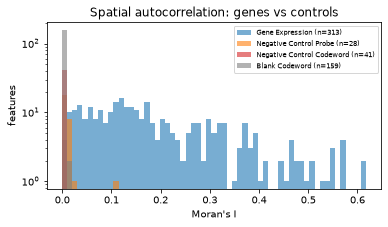

In [4]:
ftype = adata.var["feature_type"].reindex(per_feature.index)
fig, ax = plt.subplots(figsize=(6, 3))
bins = np.linspace(np.nanmin(per_feature), np.nanmax(per_feature), 60)
for t, c in [("Gene Expression", "tab:blue"), ("Negative Control Probe", "tab:orange"),
             ("Negative Control Codeword", "tab:red"), ("Blank Codeword", "tab:gray")]:
    ax.hist(per_feature[ftype == t].dropna(), bins=bins, alpha=0.6, color=c, label=f"{t} (n={int((ftype == t).sum())})")
ax.set(xlabel="Moran's I", ylabel="features", yscale="log", title="Spatial autocorrelation: genes vs controls")
ax.legend(fontsize=7)
plt.show()

**Transcript-level QC** (`transcript_qc`) needs the 670 MB transcript table: the fraction of decoded
transcripts that fall inside a segmented cell (FTC) and the negative-codeword false discovery rate (FDR, the
share of gene calls expected to be false given how often the negative features fire). Transcripts are filtered
at Q20, the cut the cell-feature matrix was built with.

In [5]:
if FETCH_TRANSCRIPTS:
    import pyarrow as pa
    import pyarrow.parquet as pq

    with timed("transcript_qc (read parquet + score)", None):
        t = pq.read_table(fetch("transcripts.parquet"), columns=["cell_id", "feature_name", "qv"],
                          filters=[("qv", ">=", 20)])
        t = t.set_column(1, "feature_name", t["feature_name"].cast(pa.string()))
        tx = t.to_pandas(strings_to_categorical=True)
        del t
        negatives = adata.var_names[adata.var["control"].to_numpy()]
        sig["transcripts"] = sam.transcript_qc(tx, negatives)
    PERF[-1]["n_cells"] = f"{len(tx):,} transcripts"
    del tx
    display(pd.Series(sig["transcripts"], name="value").to_frame())
else:
    print("skipped (SAM_FETCH_TRANSCRIPTS=0)")

,value
status,ok
frac_tx_in_cells,0.932
fdr,0.002
n_transcripts,34493510
n_unassigned,2350331
n_negative_tx,50794
n_genes_detected,313
n_negatives_detected,228


**What the signal QC says.**

- **Genes carry tissue structure, controls do not.** Median Moran's I is 0.152 for genes and -0.0002 for the
  controls, and 98.4 % of the 313 genes sit above the controls' 95th percentile. Almost every panel gene is
  spatially patterned; the controls look like scattered background, as they should.
- **Background is low.** Over the whole section, gene counts outnumber control counts about 580 to 1
  (log2 ratio 9.18). Only 18.1 % of cells have any control count at all, and among those, 0.013 % (about 4
  cells) have no more gene signal than control signal.
- **Depth is typical of a 313-gene panel.** Median 164 transcripts per cell, 1.17 per µm² of cell area; 88.3 %
  of the cell-by-feature matrix is zero. A median detection entropy of 0.91 means a cell's counts are spread
  over many genes rather than piled on one or two.
- **Transcripts.** 93.2 % of the 34.5 million Q20 transcripts fall inside a segmented cell, and the
  negative-codeword FDR is 0.002: about 1 gene call in 500 is expected to be a false decoding.

In short: a high-quality section. Whatever looks weak in the labels below is not explained by missing signal.

## 3. An annotation to evaluate

The annotation is deliberately simple. Cells with fewer than 10 gene counts are set aside (too little
information to label); the rest are log-normalised, reduced to 30 principal components and clustered with
Leiden (resolution 1.0). Each cluster is then named after the marker set with the highest mean
`scanpy.tl.score_genes` score.

The marker dictionary is curated for this panel from canonical lineage markers, covering the cell types
annotated in this section by Janesick et al. 2023 and in the breast cancer atlas of Wu et al., *Nat Genet*
2021 ([10.1038/s41588-021-00911-1](https://doi.org/10.1038/s41588-021-00911-1)). `ACTA2` sits in two sets on
purpose (myoepithelial and smooth-muscle cells both express it); the purity metrics ignore a marker two sets
share. Mast cells and adipocytes get a set although no cluster may end up named after them: the metrics then
report them as types without cells, which is information too.

In [6]:
MARKERS = {
    "Tumor epithelial": ["EPCAM", "KRT8", "KRT7", "CDH1", "ERBB2", "FOXA1", "GATA3", "TACSTD2"],
    "Myoepithelial": ["KRT5", "KRT14", "KRT15", "KRT6B", "ACTA2"],
    "Fibroblast": ["LUM", "POSTN", "DPT", "PDGFRA", "FBLN1", "CCDC80", "SFRP4"],
    "Endothelial": ["PECAM1", "VWF", "CLDN5", "KDR", "CD93", "EGFL7", "CLEC14A"],
    "Pericyte/SMC": ["MYH11", "ACTG2", "PDGFRB", "ACTA2"],
    "Macrophage": ["CD68", "CD163", "C1QA", "C1QC", "AIF1", "MRC1"],
    "T cell": ["CD3D", "CD3E", "CD3G", "TRAC", "CD247", "CD8A"],
    "B cell": ["MS4A1", "CD79A", "CD79B", "CD19", "BANK1"],
    "Plasma cell": ["MZB1", "TNFRSF17", "DERL3"],
    "Mast cell": ["CPA3", "TPSAB1", "KIT", "HDC"],
    "Adipocyte": ["ADIPOQ", "LEP"],
}
missing = sorted({g for v in MARKERS.values() for g in v} - set(adata.var_names))
print("markers off the panel:", missing or "none")

with timed("annotation (normalise, PCA, kNN, Leiden, naming)", None):
    genes = adata[:, ~adata.var["control"].to_numpy()].copy()
    for k in list(genes.obsp):   # moran_signal's graph spans all cells; the spatial metrics rebuild it
        del genes.obsp[k]
    genes.uns.pop("spatial_neighbors", None)
    genes.X = genes.layers["counts"].copy()
    sc.pp.filter_cells(genes, min_counts=10)
    sc.pp.normalize_total(genes)
    sc.pp.log1p(genes)
    sc.pp.pca(genes, n_comps=30, random_state=0)
    sc.pp.neighbors(genes, n_neighbors=15, random_state=0)
    sc.tl.leiden(genes, resolution=1.0, flavor="igraph", n_iterations=2, random_state=0)
    for name, gs in MARKERS.items():
        sc.tl.score_genes(genes, gs, score_name=f"score: {name}", random_state=0)
    scores = genes.obs[[f"score: {n}" for n in MARKERS]].set_axis(list(MARKERS), axis=1)
    by_cluster = scores.groupby(genes.obs["leiden"], observed=True).mean()
    names = by_cluster.idxmax(axis=1)
    genes.obs["cell_type"] = pd.Categorical(genes.obs["leiden"].map(names).astype(str))
PERF[-1]["n_cells"] = genes.n_obs

print(f"{adata.n_obs - genes.n_obs:,} cells with < 10 gene counts set aside; {genes.n_obs:,} annotated")
naming = pd.DataFrame({"named": names, "best score": by_cluster.max(axis=1),
                       "runner-up": by_cluster.apply(lambda r: r.nlargest(2).index[1], axis=1),
                       "runner-up score": by_cluster.apply(lambda r: r.nlargest(2).iloc[1], axis=1),
                       "cells": genes.obs["leiden"].value_counts()})
naming.sort_values(["named", "cells"], ascending=[True, False])

markers off the panel: none


3,780 cells with < 10 gene counts set aside; 164,000 annotated


,named,best score,runner-up,runner-up score,cells
leiden,,,,,
1,B cell,0.719,Fibroblast,0.282,4491
9,Endothelial,0.722,Pericyte/SMC,0.446,12587
12,Fibroblast,1.225,Pericyte/SMC,0.258,14839
11,Fibroblast,0.854,Pericyte/SMC,0.619,6854
8,Macrophage,0.714,Fibroblast,0.448,13072
7,Macrophage,0.627,Tumor epithelial,0.142,3232
4,Myoepithelial,1.010,Pericyte/SMC,0.702,6380
15,Plasma cell,0.720,Fibroblast,0.439,4748
2,T cell,0.604,Fibroblast,0.321,20684


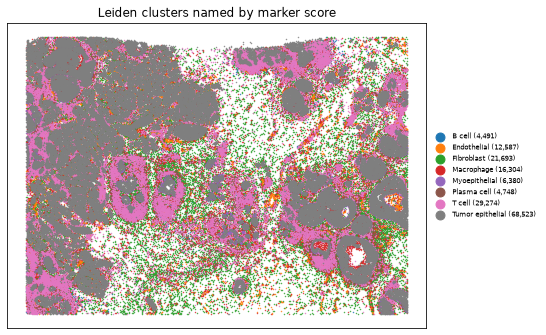

In [7]:
TYPES = sorted(genes.obs["cell_type"].cat.categories)
PALETTE = dict(zip(TYPES, plt.get_cmap("tab10").colors))
xy = genes.obsm["spatial"]
fig, ax = plt.subplots(figsize=(8, 5.5))
for t in TYPES:
    m = (genes.obs["cell_type"] == t).to_numpy()
    ax.scatter(xy[m, 0], xy[m, 1], s=0.2, color=PALETTE[t], label=f"{t} ({m.sum():,})", rasterized=True)
ax.set(aspect="equal", xticks=[], yticks=[], title="Leiden clusters named by marker score")
ax.invert_yaxis()
ax.legend(markerscale=20, fontsize=7, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()

## 4. The reference-free battery

With no ground truth, four questions can still be asked of the labels:

- **Internal validity** (`internal_validity`): are the labels compact and separated in the PCA embedding the
  clusters came from? Silhouette and its two-label variant, neighbourhood purity, orbital medoid,
  Ward-PropMatch, average similarity and their geometric mean (`integrated`); the quadratic parts use a random
  2,000-cell subsample. Leiden partitions this same embedding, so these numbers start biased upwards: they say
  the clustering is internally consistent, not that the names are right.
- **Marker-program fidelity** (`marker_program_fidelity`): within each type, does the type's own marker load
  rank its cells above all other cells (AUC-ROC) and by how much (Cohen's d)? The markers also named the
  clusters, so a low value is the informative one: a type whose own program does not set it apart.
- **Marker purity** (`crisp_purity`, `mecr`, `pmp`): do markers of different lineages turn up in the same cell?
  CRISP purity is the share of marker-positive cells that detect only one lineage; MECR the co-detection rate of
  mutually exclusive marker pairs; both are compared to a null where each marker is detected independently at
  its own rate (`vs_null`: 0 = perfectly exclusive, 1 = no better than chance). PMP is the share of a cell's
  marker counts that belong to its assigned type.
- **Per-cell confidence** (`per_cell_confidence`): from the marker scores alone, how decisive is each cell?
  The margin between the best and second-best set (high = clear), and the normalised entropy (0 = decisive,
  1 = guessing).

In [8]:
n = genes.n_obs
bat = {}
with timed("internal_validity", n):
    bat["internal"] = sam.internal_validity(genes, "cell_type", embedding="X_pca")
with timed("marker_program_fidelity", n):
    bat["fidelity"] = sam.marker_program_fidelity(genes, "cell_type", MARKERS)
with timed("crisp_purity", n):
    bat["crisp"] = sam.crisp_purity(genes, MARKERS)
with timed("mecr", n):
    bat["mecr"] = sam.mecr(genes, MARKERS)
with timed("pmp", n):
    bat["pmp"] = sam.pmp(genes, MARKERS, "cell_type")
with timed("per_cell_confidence", n):
    bat["confidence"] = sam.per_cell_confidence(genes, MARKERS)

iv = bat["internal"]
headline = {
    "internal: integrated (0-1)": iv["integrated"],
    "internal: silhouette (-1..1)": iv["silhouette"],
    "internal: 2-label silhouette": iv["silhouette_2label"],
    "internal: neighbourhood purity": iv["neighborhood_purity"],
    "internal: Davies-Bouldin (lower = better)": iv["davies_bouldin"],
    "fidelity: mean AUC": bat["fidelity"]["mean_auc"],
    "fidelity: mean Cohen's d": bat["fidelity"]["mean_cohens_d"],
    "CRISP purity": bat["crisp"]["crisp_purity"],
    "CRISP purity under the null": bat["crisp"]["crisp_purity_null"],
    "CRISP vs null (0 = exclusive, 1 = chance)": bat["crisp"]["vs_null"],
    "MECR": bat["mecr"]["mecr"],
    "MECR vs null": bat["mecr"]["vs_null"],
    "mean PMP": bat["pmp"]["mean_pmp"],
    "mean marker margin": bat["confidence"]["mean_margin"],
    "mean marker entropy (0-1)": bat["confidence"]["mean_entropy"],
}
print("types with no cell in the annotation:", sorted(set(MARKERS) - set(TYPES)))
print("labels without an on-panel marker set:", bat["fidelity"]["labels_without_markers"])
pd.Series(headline, name="value").to_frame()

types with no cell in the annotation: ['Adipocyte', 'Mast cell', 'Pericyte/SMC']
labels without an on-panel marker set: []


,value
internal: integrated (0-1),8.031e-01
internal: silhouette (-1..1),2.256e-01
internal: 2-label silhouette,3.855e-01
internal: neighbourhood purity,9.490e-01
internal: Davies-Bouldin (lower = better),1.810e+00
fidelity: mean AUC,9.411e-01
fidelity: mean Cohen's d,3.537e+00
CRISP purity,2.428e-02
CRISP purity under the null,1.890e-05
"CRISP vs null (0 = exclusive, 1 = chance)",9.757e-01


Per type, the same evidence side by side: fidelity, mean PMP, and how often the per-cell marker argmax
(computed without the labels) agrees with the cluster's name.

In [9]:
obs = genes.obs
marker_argmax = scores.idxmax(axis=1)
per_type = pd.DataFrame({
    "cells": obs["cell_type"].value_counts(),
    "fidelity AUC": {t: v["auc"] for t, v in bat["fidelity"]["per_type"].items()},
    "Cohen's d": {t: v["cohens_d"] for t, v in bat["fidelity"]["per_type"].items()},
    "mean PMP": obs.groupby("cell_type", observed=True)["sam_pmp"].mean(),
    "median margin": obs.groupby("cell_type", observed=True)["sam_marker_margin"].median(),
    "marker argmax agrees": (marker_argmax == obs["cell_type"].astype(str)).groupby(obs["cell_type"], observed=True).mean(),
}).sort_values("fidelity AUC")
per_type

,cells,fidelity AUC,Cohen's d,mean PMP,median margin,marker argmax agrees
B cell,4491.0,0.885,5.538,0.268,0.679,0.594
Macrophage,16304.0,0.927,2.588,0.316,1.095,0.606
Tumor epithelial,68523.0,0.942,2.048,0.890,8.000,0.961
Endothelial,12587.0,0.943,3.629,0.357,1.400,0.589
Fibroblast,21693.0,0.949,2.682,0.639,4.964,0.854
Myoepithelial,6380.0,0.953,3.329,0.285,1.086,0.629
Plasma cell,4748.0,0.959,5.355,0.169,1.286,0.578
T cell,29274.0,0.970,3.130,0.350,0.833,0.602
Adipocyte,NaN,NaN,NaN,NaN,NaN,NaN
Mast cell,NaN,NaN,NaN,NaN,NaN,NaN


**What the battery says.**

- **The labels are internally consistent, as a clustering.** 94.9 % of each cell's 30 nearest neighbours in PCA
  space share its label, and the integrated score is 0.80 (of 1). The silhouette is only 0.23: the types
  touch in expression space rather than forming separate islands, which is common for 300-gene panels.
  Remember the bias named above: Leiden drew these borders in this very embedding.
- **Each type's own markers set it apart.** Mean fidelity AUC 0.94 (range 0.89 for B cells to 0.97 for T
  cells), mean Cohen's d 3.5. No type is named after a program its cells do not express. Pericyte/SMC, mast
  cells and adipocytes got no cluster (no Leiden cluster scored highest for them), so this annotation cannot
  report those cells at all; the metrics cannot see a type that was never labelled.
- **Per cell, the lineages are not exclusive.** At a threshold of one count, 97.6 % of marker-positive cells
  detect markers of two or more lineages (CRISP purity 0.024), and `vs_null` 0.98 says that is barely fewer
  than if every marker were detected independently. Exclusive lineage pairs co-occur 80 % as often as chance
  (MECR `vs_null` 0.80). Some of this is genuine co-expression, but much is transcripts from neighbouring
  cells, which section 5 measures.
- **Purity splits tumour from everything else.** Mean PMP is 0.60 overall, but 0.89 in tumour epithelium
  against 0.17 to 0.36 in plasma, B, myoepithelial, macrophage, T and endothelial cells: in those cells most
  of the lineage-marker counts belong to *another* type. The same split shows in confidence: the median
  margin is 8.0 for tumour cells and 0.7 to 1.4 for immune and endothelial cells, and the per-cell marker
  argmax agrees with the cluster name for 96 % of tumour cells but only 58 to 63 % of immune, endothelial
  and myoepithelial cells.

One label to look at twice: "T cell" covers 29,274 cells (18 % of the annotated cells), much of it in broad
bands around the tumour nests on the map above. Its largest cluster (20,684 cells) has the weakest best score
of any non-tumour cluster (0.60, runner-up fibroblast 0.32), the median margin of T-labelled cells is 0.83
and the per-cell argmax agrees with "T cell" for 60 % of them. The metrics do not show the band is wrong, but
they give little support that all of it is T cells rather than a mixed immune-stromal border.

Plainly: the clusters are real and the names match their programs, but outside the tumour the evidence in
any single cell is weak. A small, scattered cell type in this section is named mainly by its cluster's
average, not by its own marker counts.

## 5. Spatial label quality

- `spatial_coherence`: for each cell, the share of its 10 nearest spatial neighbours with the same label. PAS
  (Percentage of Abnormal Spots) is the share of cells whose label differs from at least 6 of 10 neighbours;
  CHAOS the mean distance to the nearest same-label cell (on standardised coordinates). Lower = smoother. They
  catch salt-and-pepper label noise, not a compact mislabelled region, and they penalise correctly labelled
  infiltrating cells (immune cells in a tumour nest), so read them as a flag, not as accuracy.
- `neighbor_contamination`: for each cell, the share of its counts on markers of the *other* types touching it
  (6 nearest neighbours). Per (source, target) pair it reports the raw value, a baseline from target cells with
  no such neighbour, the **excess** over that baseline and a permutation p-value (199 permutations): the excess
  is the part that looks like spillover from the neighbour rather than the cell's own expression. It also reports `split_slope` and `split_corr` (regressing/correlating contaminant marker share against the source type's share of each target cell's spatial neighbours, after SPLIT) and, when `obsm['spatial']` is present, `distance_corr` and `distance_curve` (contaminant share vs distance to the nearest source cell, after CellSPA).


In [10]:
with timed("spatial_coherence", n):
    spa = {"coherence": sam.spatial_coherence(genes, "cell_type")}
with timed("neighbor_contamination", n):
    spa["contamination"] = sam.neighbor_contamination(genes, MARKERS, "cell_type")

coh, con = spa["coherence"], spa["contamination"]
pd.Series({"PAS (share of abnormal cells)": coh["pas"], "CHAOS": coh["chaos"],
           "mean same-label neighbour share": coh["mean_coherence"],
           "mean neighbour contamination": con["mean_contamination"],
           "cells evaluable for contamination": con["n_evaluable"]}, name="value").to_frame()

,value
PAS (share of abnormal cells),0.422
CHAOS,0.008
mean same-label neighbour share,0.556
mean neighbour contamination,0.075
cells evaluable for contamination,117929.000


In [11]:
spatial_by_type = pd.DataFrame({
    "same-label neighbours": obs.groupby("cell_type", observed=True)["sam_spatial_coherence"].mean(),
    "abnormal (PAS) share": (obs["sam_spatial_coherence"] <= 0.4).groupby(obs["cell_type"], observed=True).mean(),
    "neighbour contamination": obs.groupby("cell_type", observed=True)["sam_neighbor_contamination"].mean(),
}).sort_values("same-label neighbours")
display(spatial_by_type)

excess = con["excess"].where(con["p_value"] < 0.01)
top = excess.stack().sort_values(ascending=False).head(8).rename("excess (p < 0.01)").to_frame()
top["raw"] = [con["source_target"].loc[s, t] for s, t in top.index]
top["baseline"] = [con["baseline"].loc[s, t] for s, t in top.index]
top.index.names = ["source (neighbour)", "target (cell)"]
top

,same-label neighbours,abnormal (PAS) share,neighbour contamination
cell_type,,,
Plasma cell,0.161,0.939,0.113
B cell,0.166,0.927,0.080
Macrophage,0.197,0.931,0.108
Myoepithelial,0.330,0.752,0.192
Endothelial,0.367,0.664,0.084
Fibroblast,0.368,0.644,0.044
T cell,0.443,0.509,0.095
Tumor epithelial,0.858,0.049,0.020


excess (p < 0.01)    raw  baseline
source (neighbour) target (cell)                                    
Tumor epithelial   T cell                     0.073  0.115     0.042
Fibroblast         T cell                     0.064  0.123     0.059
                   Macrophage                 0.063  0.121     0.058
Tumor epithelial   Myoepithelial              0.057  0.180     0.123
                   Macrophage                 0.057  0.100     0.043
Fibroblast         B cell                     0.055  0.116     0.062
                   Plasma cell                0.049  0.126     0.077
Tumor epithelial   Plasma cell                0.048  0.090     0.042

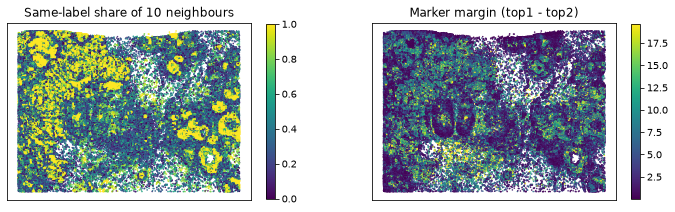

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, col, title in [(axes[0], "sam_spatial_coherence", "Same-label share of 10 neighbours"),
                       (axes[1], "sam_marker_margin", "Marker margin (top1 - top2)")]:
    v = obs[col].to_numpy()
    im = ax.scatter(xy[:, 0], xy[:, 1], c=v, s=0.3, cmap="viridis", rasterized=True,
                    vmin=np.nanquantile(v, 0.02), vmax=np.nanquantile(v, 0.98))
    ax.set(aspect="equal", xticks=[], yticks=[], title=title)
    ax.invert_yaxis()
    fig.colorbar(im, ax=ax, shrink=0.7)
plt.show()

**What the spatial metrics say.**

- **Tumour is spatially compact, the rest is interspersed.** On average 56 % of a cell's 10 nearest neighbours
  share its label, and PAS is 0.42: 42 % of cells disagree with at least 6 of their 10 neighbours. That number
  is almost all non-tumour: PAS is 0.05 for tumour epithelium and 0.51 to 0.94 for T, fibroblast, endothelial,
  myoepithelial, macrophage, B and plasma cells. Immune and stromal cells in a tumour are thin, mixed bands
  between nests, so a high PAS here is anatomy, not label noise; that is why PAS is a flag and not accuracy.
- **Neighbours leak into each other.** A cell carries on average 7.5 % of its counts on the markers of the
  other types touching it. The excess over cells of the same type with no such neighbour is clearest from
  tumour epithelium into T cells (11.5 % next to tumour against 4.2 % away from it, +7.3 points) and from
  fibroblasts into T cells, macrophages and B cells (+5.5 to +6.4 points); all the pairs listed have a
  permutation p < 0.01. Tumour cells themselves carry only 2.0 %: in a large nest most of their
  neighbours are tumour too.
- **The three per-type measures agree.** Tumour epithelium has the highest same-label share (0.86), the
  highest median marker margin (8.0) and the least contamination (2.0 %); plasma, B and macrophage cells have
  the lowest share (0.16 to 0.20), margins of 0.7 to 1.3 and 8 to 11 % contamination. The maps show the same
  split in space: compact, coherent tumour nests, and a stroma between them where labels mix and margins are
  small.

This ties back to section 4: the low per-cell purity of immune and stromal labels is, to a measurable degree,
spillover from neighbouring tumour and fibroblast cells. A cleaner annotation of those cells would start from
better segmentation or a spillover correction, not from a different clustering.

## 6. Run time and memory on the full section

Wall time and peak resident memory (RSS) of the notebook's Python process, per step. `rss_at_start_gb` is what
was already held (the section, the annotated copy); the peak includes it. Measured on the run committed with
this notebook; other machines will differ.

In [13]:
import platform

perf = pd.DataFrame(PERF)
print(f"{os.cpu_count()} logical CPUs, Python {platform.python_version()}, {platform.system()}")
print(f"total wall time {perf['wall_s'].sum():.0f} s; highest peak RSS {perf['peak_rss_gb'].max():.1f} GB")
perf

128 logical CPUs, Python 3.12.13, Linux
total wall time 86 s; highest peak RSS 4.0 GB


,step,n_cells,wall_s,rss_at_start_gb,peak_rss_gb
0,load section,167780,0.6,0.43,0.64
1,moran_signal,167780,11.6,0.64,1.62
2,signal_to_noise + sparsity + entropy + tx,167780,0.5,1.62,1.99
3,transcript_qc (read parquet + score),"34,493,510 transcripts",2.3,1.65,4.00
4,"annotation (normalise, PCA, kNN, Leiden, naming)",164000,54.7,3.35,3.59
5,internal_validity,164000,3.2,2.72,3.15
6,marker_program_fidelity,164000,0.7,2.98,3.01
7,crisp_purity,164000,3.5,3.01,3.03
8,mecr,164000,3.5,3.03,3.03
9,pmp,164000,0.4,3.03,3.05


**Scale.** Every metric in sections 2, 4 and 5 ran on all cells: 167,780 for signal QC and 164,000 for the
label metrics. Leiden clustering, not the evaluation, dominates the run time. The longest evaluation step is
`moran_signal` (541 features, permutation test), and `internal_validity` stays at a few seconds at this size
because its quadratic parts use a 2,000-cell subsample. The highest peak (4.0 GB) is reading the transcript
table for transcript QC; each label metric adds at most about 0.4 GB to what the notebook already holds (the
section plus its annotated copy), so none of them builds a cell-by-cell matrix.

**Take-home for this section.** The data are good (section 2), the clusters are coherent and carry their
programs (section 4), and the main weakness of the labels is per-cell marker purity outside the tumour, which
section 5 traces in part to spillover from neighbouring cells. None of these numbers says a label is *correct*:
for that you need a reference, and the package's reference-based metrics (`nmp`, `ncp`, `coexpression_similarity`)
are the next step.